# 4th down: go for it, kick a field goal, or punt?

For every 4th-down situation (yards to go × field position) we want the call with the highest
**expected points**, together with the **probabilities** behind it.

**Method**
1. Estimate the probabilities from NFL play-by-play data 2018–2025 (nflverse): yards gained per play,
   P(1st down | d), P(FG good | x), punt distances, and what coaches actually do.
2. Model the game as a **Markov chain** with state (down, yards to go, field position) that runs until
   the **next score** (the absorbing states). Solving the chain gives expected points (EP) for every state.
3. On 4th down compare EP after each action. The best one is the **handbook**.
4. **Monte Carlo**: simulate the chain to check the exact solution, and bootstrap the data
   to get P(going for it is the best call) instead of a plain yes/no.

**Terms**
- `pos` = yards to the opponent's end zone (pos 75 = own 25, pos 50 = midfield, pos 5 = opponent's 5).
- `togo` = yards to go for a 1st down.
- **EP** = expected value of the next score, from the view of the team with the ball (+7 / +3 / +2, or negative if the opponent scores next).
- **Break-even probability** = the conversion probability at which going for it is exactly as good as the best kick.

The slow part (bootstrap, ~10 min) is cached in `cache/`. Set `RECOMPUTE = True` to redo it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fourth_down import analysis as A, plots, simulate

pd.set_option("display.precision", 3)
RECOMPUTE = False

s = A.setup()                                   # data, probabilities, Markov chain, EP, handbook
boot = A.bootstrap(s, n_boot=200, recompute=RECOMPUTE)
hb = A.add_bootstrap(s.handbook, boot)          # handbook + bootstrap probabilities
scored = A.score_decisions(s)                   # every real 4th down, valued by the model
n_games = A.team_games(s.pbp)
print(f"{len(s.pbp):,} plays, {len(s.decisions):,} neutral 4th-down decisions, {n_games:,} team-games")

371,798 plays, 18,921 neutral 4th-down decisions, 4,254 team-games


## 1. The probabilities from the data

**Conversion probability p(d).** 4th-down attempts are rare, so the model uses 3rd and 4th downs together
(same situation: one play to gain the yards). The error bars are 95% confidence intervals from the normal
approximation, p̂ ± 1.96·√(p̂(1−p̂)/n). They are wide for 4th down only, which is why we pool.

,3rd + 4th down rate,4th down only rate,3rd + 4th down n,4th down only n
ydstogo,,,,
1,0.700,0.690,5641,1426
2,0.576,0.592,3456,448
3,0.529,0.540,3178,272
4,0.488,0.552,3034,174
5,0.434,0.451,3092,113
6,0.429,0.441,2891,59
7,0.384,0.456,2731,57
8,0.355,0.393,2459,28
9,0.305,0.278,2079,18


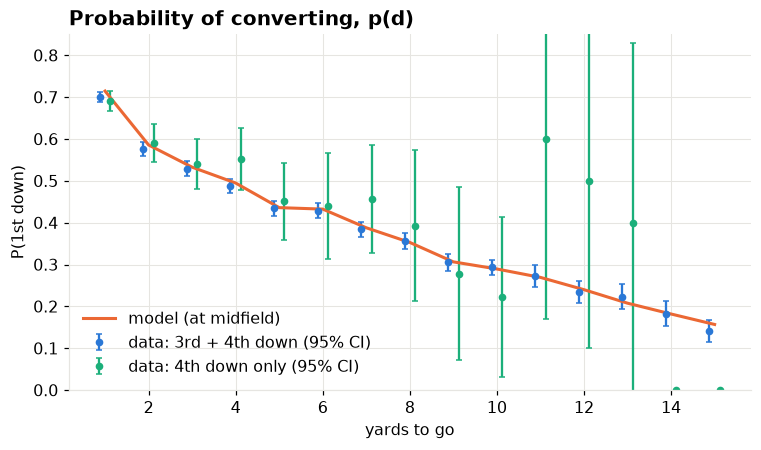

In [2]:
fig, table = plots.conversion_rates(s.pbp, s.handbook)
table

**Field goals.** Logistic regression fitted by maximum likelihood: p_FG(x) = 1 / (1 + e^-(b0 + b1·x)).

b0, b1 = [ 6.181 -0.105]  kick distance = pos + 18


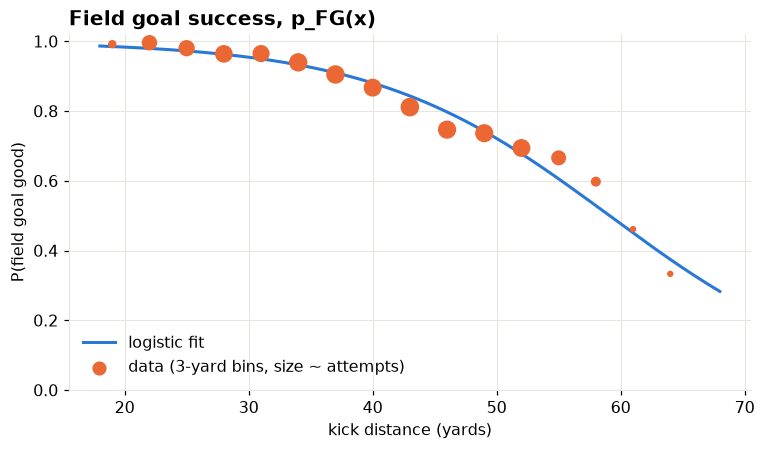

In [3]:
plots.field_goal_curve(s.pbp, s.params)
print("b0, b1 =", np.round(s.params.fg_logit, 3), " kick distance = pos +", s.params.fg_offset)

**Punts.** The model draws the opponent's starting position from real punts from a similar spot.

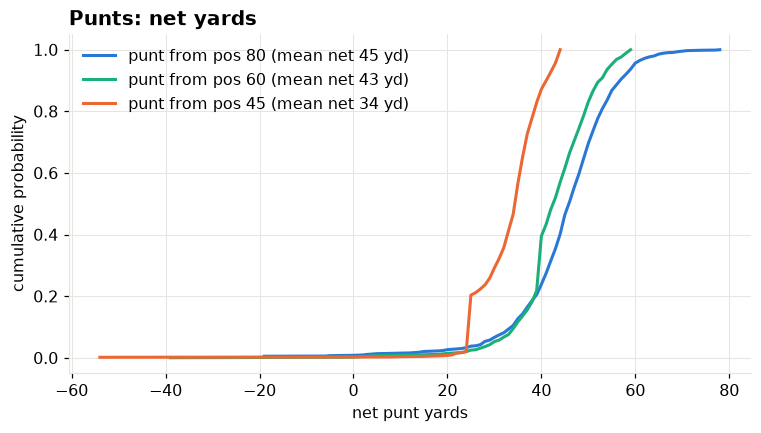

In [4]:
plots.punt_distance(s.params);

**What coaches do** (quarters 1–3, not the last 2 minutes of the half). This is the baseline policy.

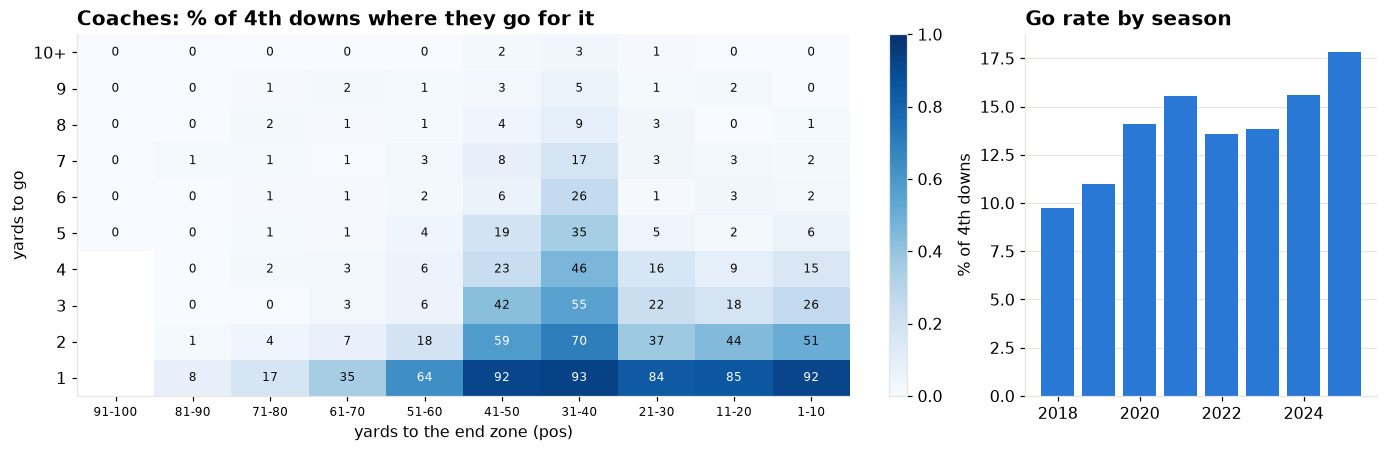

In [5]:
plots.coach_go_rates(s.decisions);

## 2. The Markov chain and expected points

EP(s) = E[next score | state s]. By the law of total expectation over what happens on the next play,

EP(s) = r(s) + Σ A(s, s′)·EP(s′)

where r(s) is the expected points scored on the play and A(s, s′) = +P(s → s′) if we keep the ball,
−P(s → s′) if the opponent gets it (their EP counts against us). That is one linear system
(I − A)·EP = r with 10,140 states. Here both teams play like the coaches.

The shaded band is the 95% bootstrap interval; the dashed line is nflverse's own EP model, for comparison.

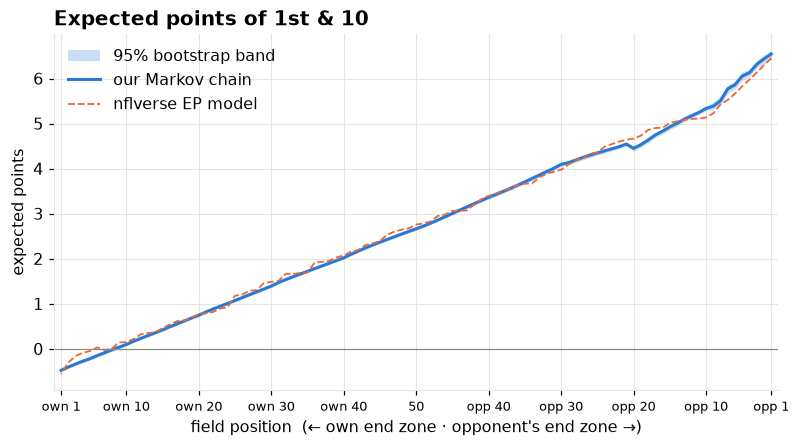

In [6]:
plots.ep_curve(s, boot);

The two models agree within about 0.2 points everywhere. The small step at the opponent's 20 is where
the model switches to red-zone play distributions (gains are shorter there because the field is short).

**Check with Monte Carlo.** Simulate the same chain play by play until someone scores, many times.
By the law of large numbers the average converges to EP, with error ≈ 1.96·s/√n (CLT).

In [7]:
sim = simulate.Simulator(s.chain, s.coach_policy, seed=1)
rows = []
for state in [(1, 10, 75), (1, 10, 50), (3, 5, 30), (4, 2, 45)]:
    x = np.array([sim.next_score(*state) for _ in range(10_000)])
    rows.append({"state (down, togo, pos)": state, "exact EP": s.ep[s.chain.index(*state)],
                 "Monte Carlo": x.mean(), "± 95%": 1.96 * x.std() / np.sqrt(len(x))})
    if state == (1, 10, 75):
        own25 = x
pd.DataFrame(rows)

,"state (down, togo, pos)",exact EP,Monte Carlo,± 95%
0,"(1, 10, 75)",1.072,1.133,0.109
1,"(1, 10, 50)",2.665,2.616,0.098
2,"(3, 5, 30)",3.037,3.061,0.080
3,"(4, 2, 45)",0.607,0.610,0.109


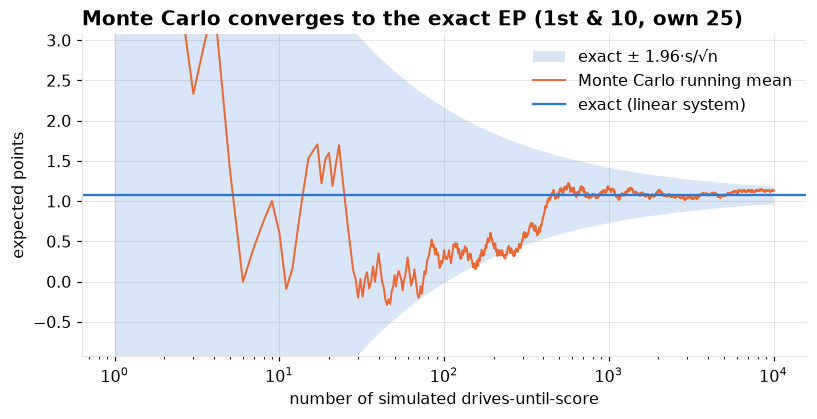

In [8]:
plots.mc_convergence(own25, s.ep[s.chain.index(1, 10, 75)], 'Monte Carlo converges to the exact EP (1st & 10, own 25)');

## 3. The handbook

For each 4th-down state, EP after going for it, kicking a field goal and punting. The best call is the
one with the highest EP. (Field goals are allowed up to 63 yards, punts from your own side up to the opponent's 30.)

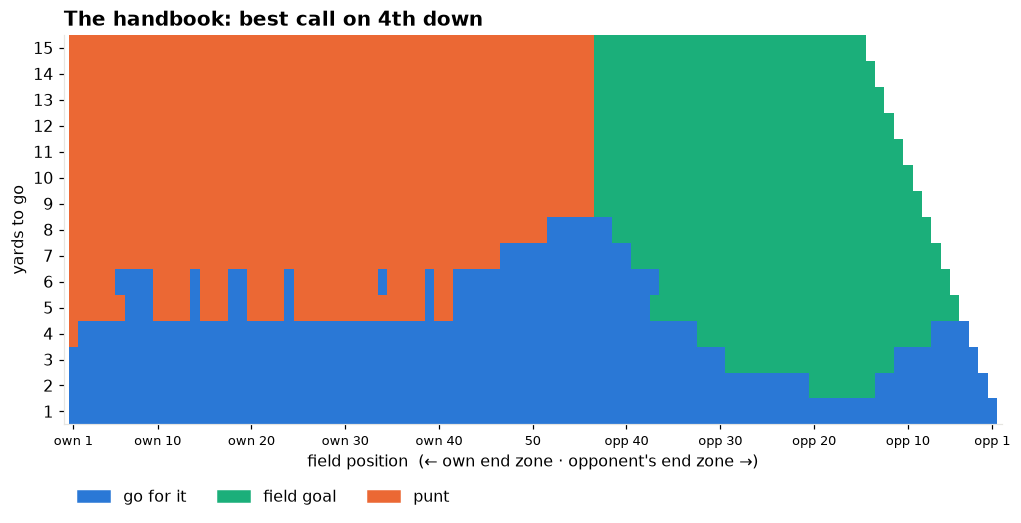

In [9]:
plots.handbook_map(hb);

The thin spikes at 4th & 5–6 in your own half are where going for it and punting are almost equal
(the punt data comes in 5-yard buckets, so the winner flips back and forth). The next plot shows the
difference there is under 0.1 EP: either call is fine.

**How much does the call matter?** EP of going for it minus EP of the best kick. Deep blue = going for it
is worth a lot; deep orange = kicking is clearly right; pale = it hardly matters.

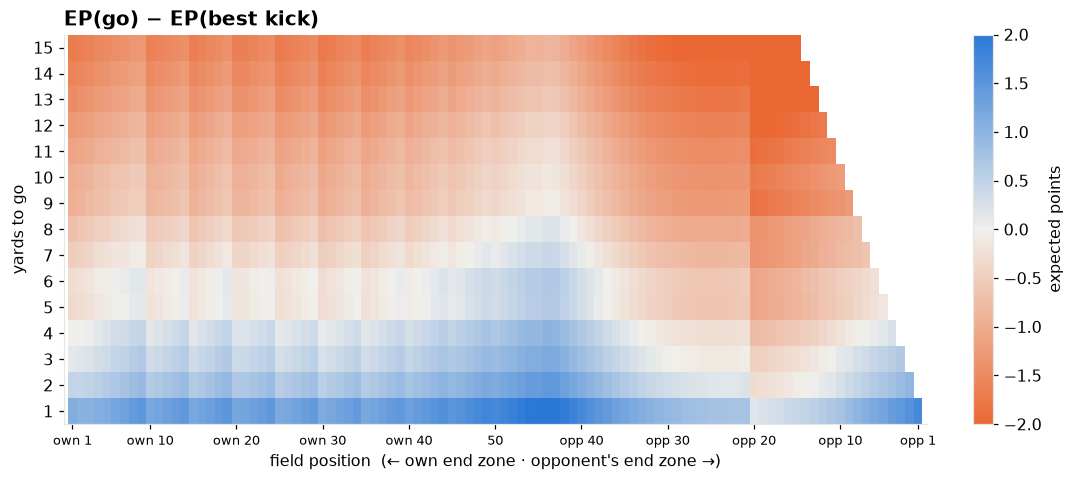

In [10]:
plots.value_map(hb, 'go_minus_kick', title='EP(go) − EP(best kick)', label='expected points', lim=2);

**In probabilities.** Going for it is right when P(convert) is above the break-even probability
p* = (EP(kick) − E[EP | fail]) / (E[EP | convert] − E[EP | fail]).

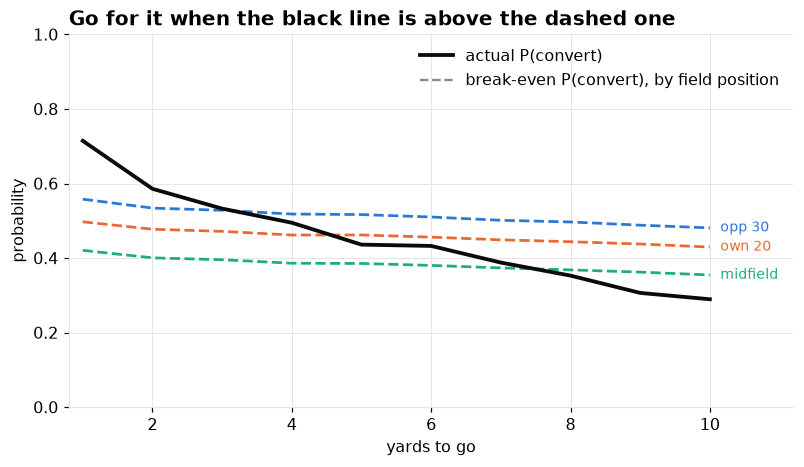

In [11]:
plots.breakeven_lines(hb);

**How sure are we?** Bootstrap: resample the data 200 times, re-estimate every probability, re-solve the chain
and redo the handbook. The share of resamples where going for it is best is P(go is best).
Solid line = 50%, dashed = 90%.

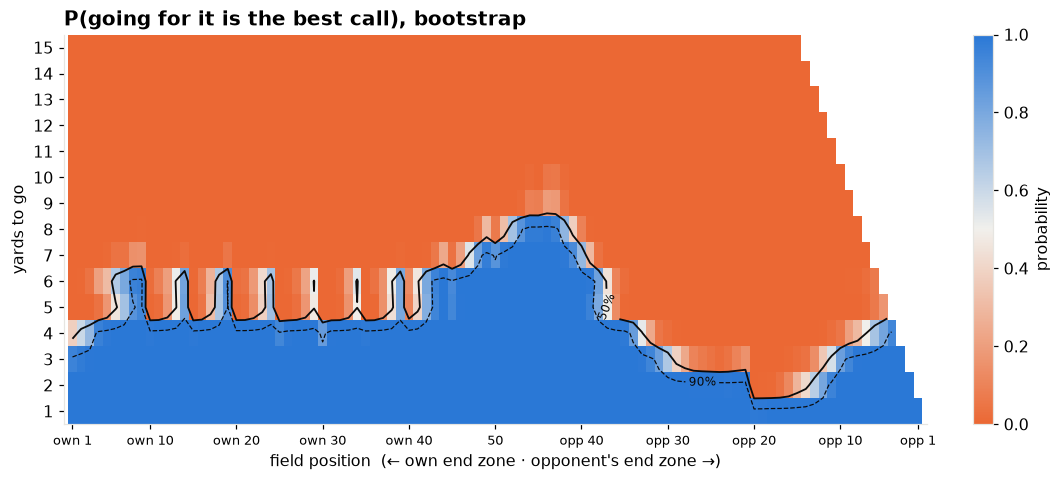

In [12]:
plots.probability_map(hb, 'p_best_go', title='P(going for it is the best call), bootstrap', label='probability');

**The handbook in one table**: in each zone, go for it with this many yards to go or fewer.

In [13]:
A.go_thresholds(s.handbook)

,zone (yards to end zone),go for it if togo ≤,otherwise
0,1-10,3,fg
1,11-20,1,fg
2,21-30,2,fg
3,31-40,3,fg
4,41-50,7,punt
5,51-60,4,punt
6,61-70,4,punt
7,71-80,4,punt
8,81-90,4,punt
9,91-100,3,punt


**What if everyone played the handbook?** The handbook above assumes everything *after* this 4th down is
played like today's coaches. Policy iteration lets both teams use the best call everywhere, re-solving
until nothing changes.

46 of 1380 cells (togo ≤ 15) change their best call


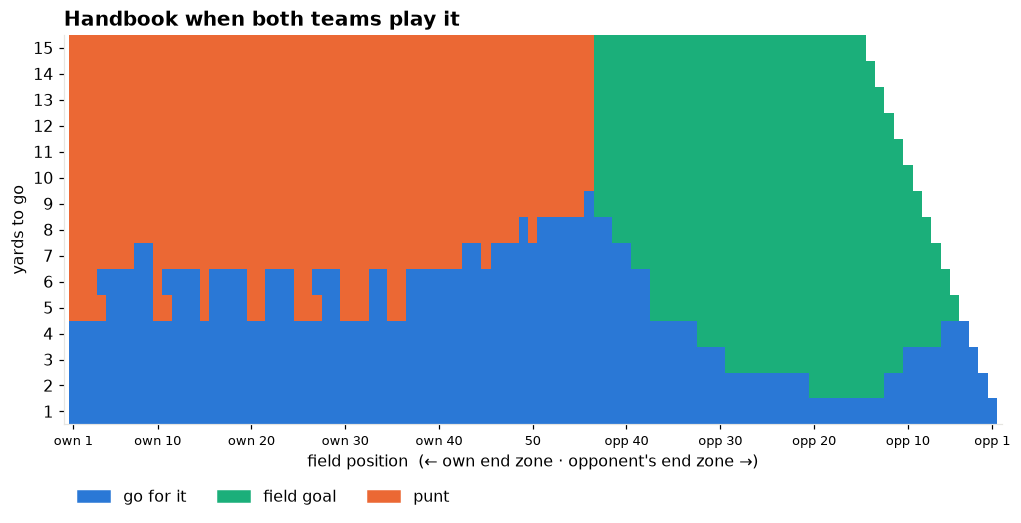

In [14]:
opt_policy, opt_ep = s.chain.optimal()
opt = s.chain.handbook(opt_ep)
changed = (opt["best"] != s.handbook["best"]) & (s.handbook["togo"] <= 15)
print(f"{changed.sum()} of {(s.handbook['togo'] <= 15).sum()} cells (togo ≤ 15) change their best call")
plots.handbook_map(opt, title="Handbook when both teams play it");

**Look up any situation** (change the numbers):

In [15]:
hb.query("togo == 4 and pos == 55")[["togo", "pos", "q_go", "q_fg", "q_punt", "best", "gain",
                                    "p_conv", "breakeven", "p_fg", "p_best_go"]]

,togo,pos,q_go,q_fg,q_punt,best,gain,p_conv,breakeven,p_fg,p_best_go
1188,4,55,0.073,NaN,-0.39,go,0.463,0.495,0.421,NaN,1.0


## 4. Coaches vs the handbook

Every real 4th-down decision in neutral situations, valued with the model.
EP lost = EP(best call) − EP(call the coach made).

In [16]:
print(f"Coaches agree with the handbook on {scored['agrees'].mean():.1%} of 4th downs")
print(f"EP lost per team-game: {scored['ep_lost'].sum() / n_games:.2f}")
pd.crosstab(scored["action"], scored["best"], margins=True).rename_axis(index="coach did", columns="handbook says")

Coaches agree with the handbook on 70.9% of 4th downs
EP lost per team-game: 0.76


handbook says,fg,go,punt,All
coach did,,,,
fg,3781,767,2,4550
go,264,2319,54,2637
punt,412,3999,7323,11734
All,4457,7085,7379,18921


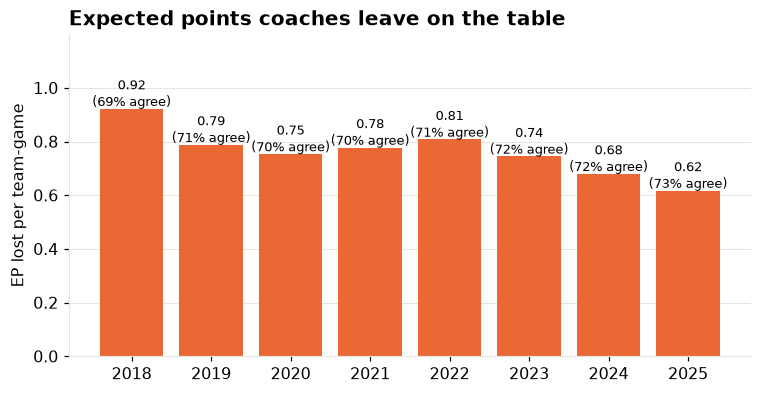

In [17]:
plots.ep_lost_by_season(scored, s.pbp);

**Where the points are lost**, the situations with the most EP lost in total:

In [18]:
A.costliest(scored, n_games)

plays  coaches_go handbook  ep_lost_per_100_games  \
togo  pos zone                                                      
1     61-70       437       0.348       go                  9.067   
2     61-70       302       0.073       go                  4.798   
1     71-80       164       0.171       go                  4.277   
      51-60       307       0.635       go                  4.025   
6-10  41-50       667       0.049       go                  3.811   
2     51-60       186       0.183       go                  3.326   
3     61-70       316       0.025       go                  2.955   
      51-60       193       0.057       go                  2.832   
6-10  31-40       574       0.143       fg                  2.774   
1     81-90        86       0.081       go                  2.521   
4     41-50       155       0.232       go                  2.470   
      51-60       211       0.057       go                  2.266   

                ep_lost_per_play  
togo  pos zone                    
1     61-70                0.883  
2     61-70                0.676  
1     71-80                1.109  
      51-60                0.558  
6-10  41-50                0.243  
2     51-60                0.761  
3     61-70                0.398  
      51-60                0.624  
6-10  31-40                0.206  
1     81-90                1.247  
4     41-50                0.678  
      51-60                0.457

**Teams**: best and worst team-seasons by EP lost per game.

In [19]:
t = A.teams(scored, s.pbp)
pd.concat([t.head(5), t.tail(5)])

go_rate  agree  ep_lost_per_game
season posteam                                  
2025   IND        0.284  0.866             0.231
2023   PHI        0.212  0.788             0.253
2024   BAL        0.115  0.770             0.286
2022   BUF        0.096  0.808             0.320
2024   DAL        0.143  0.857             0.327
2018   ARI        0.036  0.690             1.279
       DET        0.080  0.653             1.302
       DEN        0.060  0.614             1.348
       JAX        0.073  0.598             1.368
       HOU        0.090  0.615             1.486

## 5. The overall best thing to do

Simple rules evaluated on the same real 4th-down situations teams faced, in expected points per game
compared with what the coaches did. When a rule doesn't go for it, it kicks a FG up to 55 yards and punts otherwise.

,rule,go_rate,ep_per_game_vs_coaches
0,Coaches (what they did),0.139,0.000
1,Never go for it,0.000,-0.619
2,Always go for it,1.000,-1.948
3,Go if togo ≤ 1,0.114,0.077
4,Go if togo ≤ 2,0.189,0.328
5,Go if togo ≤ 3,0.266,0.488
6,Go if togo ≤ 4,0.339,0.572
7,Go if togo ≤ 5,0.417,0.528
8,Go if togo ≤ 6,0.490,0.503
9,Go if togo ≤ 7,0.562,0.395


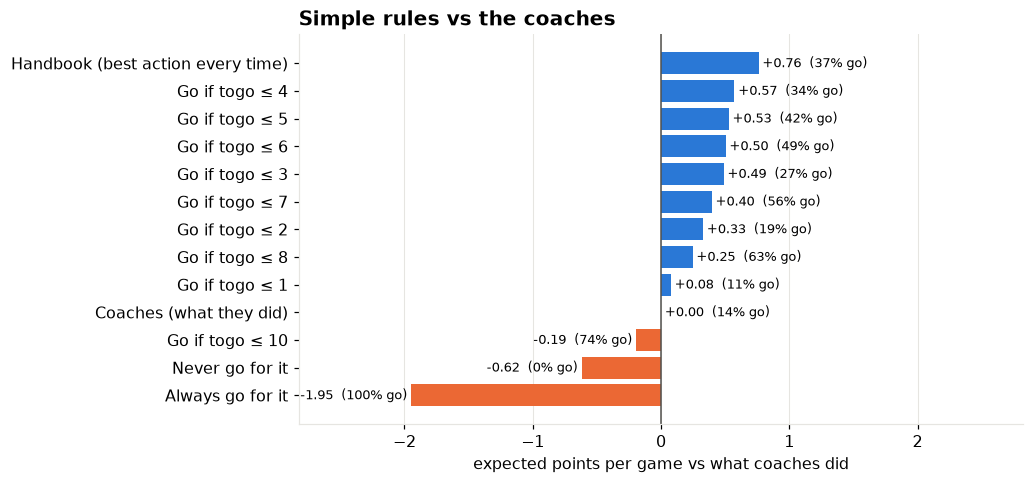

In [20]:
rules = A.compare_rules(scored, n_games)
plots.rules_bar(rules)
rules

## 6. Fun and unexpected situations

All numbers side by side. "coaches go %" is from real plays with the same yards to go, within ±2 yards of
the field position.

In [21]:
A.situations(s, hb, scored).set_index("situation")

,togo,pos,EP go,EP fg,EP punt,best,EP gained vs 2nd best,P(convert),break-even P,P(FG good),"P(go is best), bootstrap",coaches go %,n real plays (±2 yd)
situation,,,,,,,,,,,,,
4th & 1 on your own 20,1,80,-0.460,NaN,-1.693,go,1.233,0.715,0.497,NaN,1.000,0.110,73
4th & 1 on your own 5,1,95,-1.557,NaN,-2.695,go,1.138,0.715,0.522,NaN,1.000,NaN,0
4th & 2 on your own 30,2,70,-0.487,NaN,-1.030,go,0.543,0.586,0.498,NaN,1.000,0.034,89
4th & 4 at your own 45,4,55,0.073,NaN,-0.390,go,0.463,0.495,0.421,NaN,1.000,0.080,113
4th & 10 at midfield,10,50,-0.704,NaN,-0.271,punt,0.433,0.289,0.355,NaN,0.000,0.016,64
No man's land: 4th & 5 at the opponent's 36,5,36,0.959,1.064,-0.179,fg,0.105,0.436,0.452,0.630,0.130,0.300,70
Long FG or punt: 4th & 8 at the opponent's 40,8,40,0.281,0.414,-0.179,fg,0.134,0.353,0.373,0.529,0.095,0.071,56
4th & 2 at the opponent's 30,2,30,2.164,1.846,-0.244,go,0.318,0.586,0.534,0.762,1.000,0.461,76
4th & 15 at the opponent's 35,15,35,-0.463,1.214,-0.183,fg,1.396,0.157,0.405,0.654,0.000,0.000,14


## 7. Side note: are coaches more cautious in the playoffs?

The model is estimated from the regular season only. Here we score the 873 playoff 4th downs
(100 games, 2018–2025, quarters 1–3) with the same handbook and compare.

**1. Go rate in the same situations.** Playoff teams face a different mix of situations, so raw go rates
aren't comparable. Instead: for each playoff 4th down, the probability that a *regular-season* coach goes for
it in that exact spot. The sum is the expected number of attempts (law of total probability), and the variance
is Σ p(1−p) (sum of independent Bernoullis), which gives a z-test.

In [22]:
from fourth_down import data
pbp_post = data.load_pbp(season_type="POST")
scored_post = A.score_decisions(s, data.fourth_down_decisions(pbp_post))
situation, clear_spots, ep_lost = A.playoffs_vs_regular(s, scored, scored_post, pbp_post)
situation

,4th downs,went for it,expected (regular-season coach),actual / expected,z,p-value
games,,,,,,
regular season,18921,2637,2657.989,0.992,-0.621,0.534
playoffs,873,123,116.972,1.052,0.844,0.399


**2. In the spots that matter most**: where the handbook clearly says go (gain ≥ 0.5 EP), how often
do coaches actually go for it? Two-proportion z-test.

,clear go spots,coaches went for it,95% CI ±,z (playoffs vs regular),p-value
regular season,4252,0.447,0.015,NaN,NaN
playoffs,171,0.456,0.075,0.246,0.806


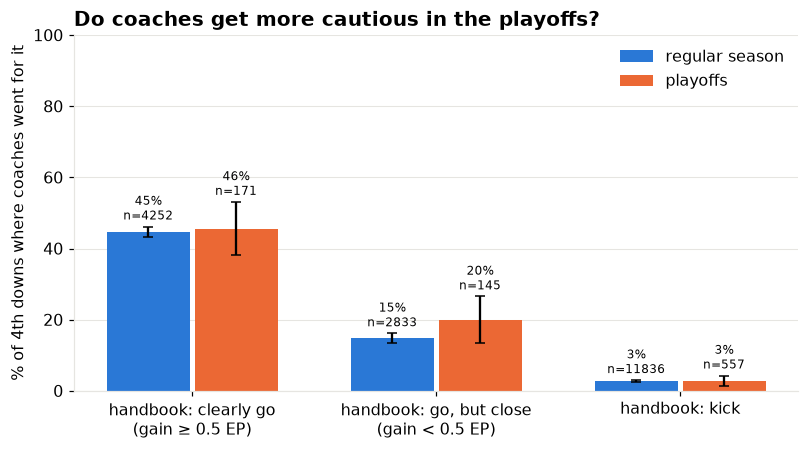

In [23]:
plots.playoff_go_rates(scored, scored_post)
clear_spots

**3. Expected points lost per game** (two-sample z-test on the per-game totals):

In [24]:
ep_lost

,team-games,EP lost per game,95% CI ±,z (playoffs vs regular),p-value
regular season,4254,0.760,0.024,NaN,NaN
playoffs,200,0.679,0.104,-1.492,0.136


Note: this only covers quarters 1–3. Any extra playoff caution could show up late in close games,
which this project leaves out on purpose.

## Caveats
- No clock and no score: EP treats every situation as an early-game one (we only use quarters 1–3 data).
- 4th-down conversions are estimated from 3rd-down plays too; defences may play differently on 4th down.
- The handbook assumes the rest of the game is played like today's coaches (section 3 shows what changes otherwise).
- Very long field goals (>55 yd) rest on the logistic curve's extrapolation, where data is thin.